In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Used_Cars_Homework.csv")

df.head(10)

,age_years,mileage_km,engine_l,power_hp,brand,fuel_type,transmission,accident_history,price_azn
0,11,97064.0,NaN,77,Hyundai,hybrid,manual,no,16950
1,10,74340.0,NaN,135,BMW,petrol,automatic,no,37335
2,6,69312.0,1.4,95,Toyota,petrol,NaN,no,30593
3,8,126280.0,NaN,89,Kia,hybrid,automatic,no,22641
4,2,42026.0,1.4,98,BMW,hybrid,automatic,no,41672
5,11,89859.0,2.0,120,Hyundai,petrol,automatic,yes,18479
6,6,124854.0,3.0,196,Toyota,diesel,automatic,no,38680
7,4,70952.0,1.8,95,BMW,petrol,automatic,no,40016
8,15,248400.0,1.8,90,Hyundai,hybrid,automatic,no,19668
9,11,153076.0,2.0,140,BMW,hybrid,automatic,no,36190


In [2]:
print("Количество строк и столбцов:")
print(df.shape)

print("\nТипы данных:")
print(df.dtypes)

print("\nКоличество пропусков:")
print(df.isnull().sum())

Количество строк и столбцов:
(300, 9)

Типы данных:
age_years             int64
mileage_km          float64
engine_l            float64
power_hp              int64
brand                   str
fuel_type               str
transmission            str
accident_history        str
price_azn             int64
dtype: object

Количество пропусков:
age_years            0
mileage_km          17
engine_l            16
power_hp             0
brand                0
fuel_type           13
transmission        10
accident_history     0
price_azn            0
dtype: int64


In [3]:
df.describe()

,age_years,mileage_km,engine_l,power_hp,price_azn
count,300.000000,283.000000,284.000000,300.000000,300.000000
mean,7.850000,118302.176678,1.901761,123.270000,27806.573333
std,4.147066,73652.009931,0.581484,39.903861,9772.778467
min,1.000000,8659.000000,1.200000,57.000000,3805.000000
25%,4.000000,54862.500000,1.400000,93.000000,21865.500000
50%,8.000000,112308.000000,1.800000,113.000000,27458.500000
75%,11.000000,166869.500000,2.500000,151.250000,34844.750000
max,15.000000,334305.000000,3.000000,218.000000,51396.000000


In [4]:
print("Минимальная цена:", df["price_azn"].min())
print("Максимальная цена:", df["price_azn"].max())
print("Средняя цена:", df["price_azn"].mean())

Минимальная цена: 3805
Максимальная цена: 51396
Средняя цена: 27806.573333333334


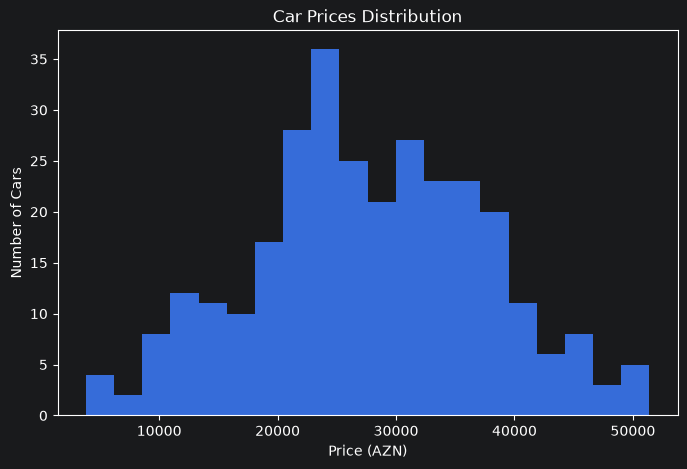

In [5]:
plt.figure(figsize=(8, 5))

plt.hist(df["price_azn"], bins=20)

plt.title("Car Prices Distribution")
plt.xlabel("Price (AZN)")
plt.ylabel("Number of Cars")

plt.show()

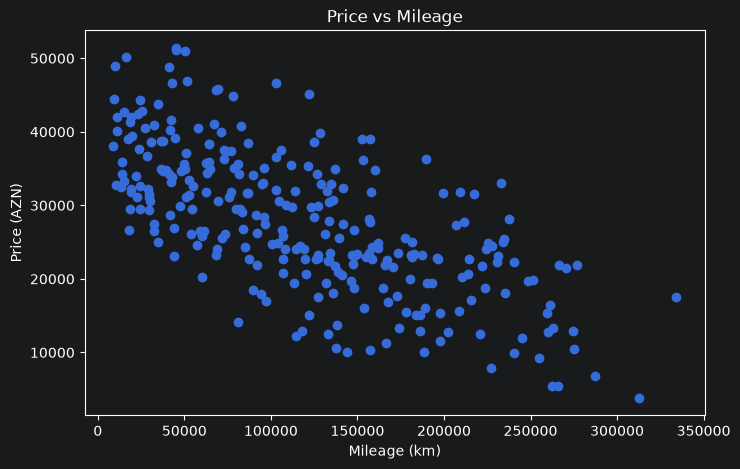

In [6]:
plt.figure(figsize=(8, 5))

plt.scatter(df["mileage_km"], df["price_azn"])

plt.title("Price vs Mileage")
plt.xlabel("Mileage (km)")
plt.ylabel("Price (AZN)")

plt.show()

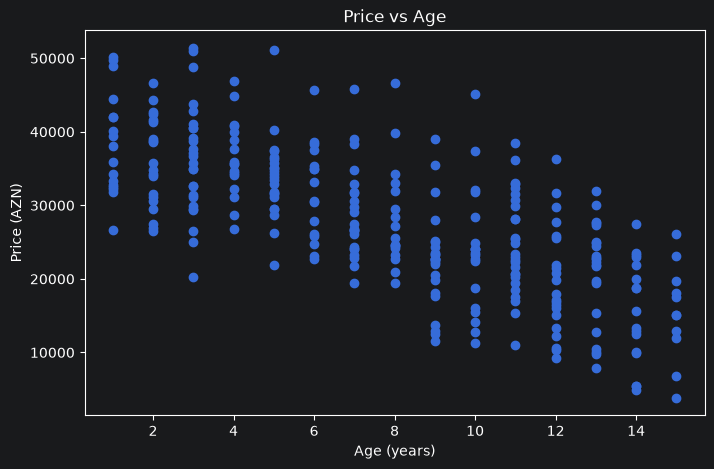

In [7]:
plt.figure(figsize=(8, 5))

plt.scatter(df["age_years"], df["price_azn"])

plt.title("Price vs Age")
plt.xlabel("Age (years)")
plt.ylabel("Price (AZN)")

plt.show()

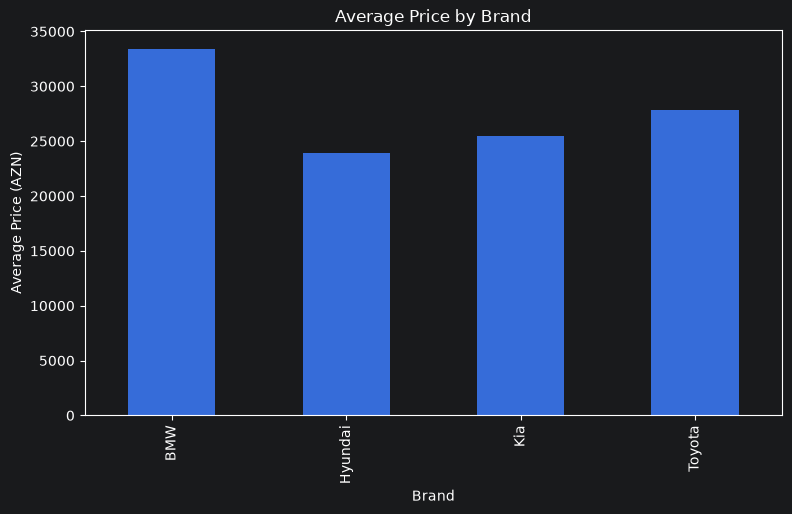

In [8]:
df.groupby("brand")["price_azn"].mean().plot(kind="bar", figsize=(9, 5))

plt.title("Average Price by Brand")
plt.xlabel("Brand")
plt.ylabel("Average Price (AZN)")

plt.show()

In [9]:
df["mileage_per_year"] = df["mileage_km"] / df["age_years"].replace(0, 1)

df.head()

,age_years,mileage_km,engine_l,power_hp,brand,fuel_type,transmission,accident_history,price_azn,mileage_per_year
0,11,97064.0,NaN,77,Hyundai,hybrid,manual,no,16950,8824.0
1,10,74340.0,NaN,135,BMW,petrol,automatic,no,37335,7434.0
2,6,69312.0,1.4,95,Toyota,petrol,NaN,no,30593,11552.0
3,8,126280.0,NaN,89,Kia,hybrid,automatic,no,22641,15785.0
4,2,42026.0,1.4,98,BMW,hybrid,automatic,no,41672,21013.0


In [10]:
X = df.drop("price_azn", axis=1)
y = df["price_azn"]

In [11]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)

Train: (240, 9)
Test: (60, 9)


In [12]:
brand_data = X_train["brand"].copy()

codes, names = pd.factorize(brand_data)

print("Factorize:")
print(codes[:10])

print("\nOne-Hot Encoding:")
print(pd.get_dummies(brand_data).head())

Factorize:
[0 1 1 0 1 0 1 1 2 0]

One-Hot Encoding:
       BMW  Hyundai    Kia  Toyota
232   True    False  False   False
59   False    False  False    True
6    False    False  False    True
185   True    False  False   False
173  False    False  False    True


In [13]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

mileage = X_train[["mileage_km"]].copy()

minmax = MinMaxScaler()
standard = StandardScaler()

print("MinMaxScaler:")
print(minmax.fit_transform(mileage)[:10])

print("\nStandardScaler:")
print(standard.fit_transform(mileage)[:10])

MinMaxScaler:
[[0.13514983]
 [0.22392721]
 [0.35681384]
 [       nan]
 [0.01963789]
 [0.82272161]
 [0.5670759 ]
 [0.34332373]
 [0.55383146]
 [0.21565135]]

StandardScaler:
[[-0.90397299]
 [-0.51018452]
 [ 0.07925867]
 [        nan]
 [-1.41634751]
 [ 2.14587856]
 [ 1.01191486]
 [ 0.0194208 ]
 [ 0.95316669]
 [-0.54689361]]


In [14]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

num_cols = ["age_years", "mileage_km", "engine_l", "power_hp", "mileage_per_year"]
cat_cols = ["brand", "fuel_type", "transmission", "accident_history"]

num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", num_pipeline, num_cols),
    ("cat", cat_pipeline, cat_cols)
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("regression", LinearRegression())
])

In [15]:
model.fit(X_train, y_train)

predictions = model.predict(X_test)

print("Model trained successfully!")

Model trained successfully!


In [16]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, predictions)
mse = mean_squared_error(y_test, predictions)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, predictions)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2:", r2)

MAE: 1414.621794685171
MSE: 2886404.319850034
RMSE: 1698.9421178633586
R2: 0.9717678175713533


In [17]:
results = pd.DataFrame({
    "Real Price": y_test.values,
    "Predicted Price": predictions,
    "Error": abs(y_test.values - predictions)
})

results.head(10)

,Real Price,Predicted Price,Error
0,34837,32094.809515,2742.190485
1,34946,33157.902122,1788.097878
2,32214,31152.656307,1061.343693
3,36190,35780.659925,409.340075
4,25000,23648.311080,1351.688920
5,26522,27360.103746,838.103746
6,22711,24210.683874,1499.683874
7,33061,32078.441815,982.558185
8,18479,19693.806537,1214.806537
9,25003,23457.433793,1545.566207


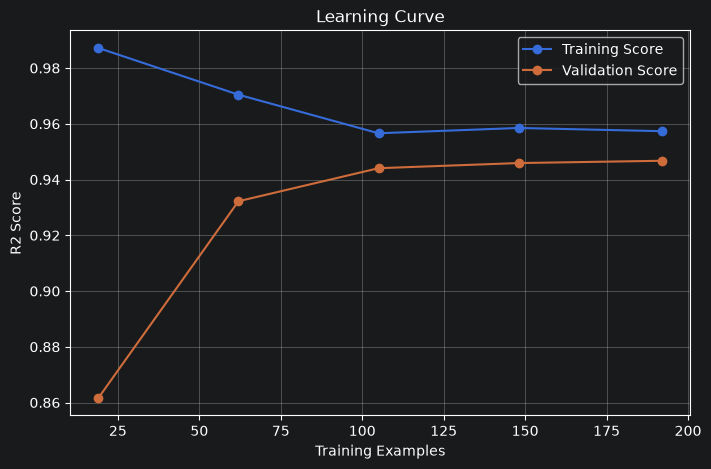

In [18]:
from sklearn.model_selection import learning_curve

sizes, train_scores, test_scores = learning_curve(
    model, X_train, y_train,
    cv=5,
    scoring="r2",
    train_sizes=np.linspace(0.1, 1.0, 5)
)

train_mean = train_scores.mean(axis=1)
test_mean = test_scores.mean(axis=1)

plt.figure(figsize=(8, 5))

plt.plot(sizes, train_mean, marker="o", label="Training Score")
plt.plot(sizes, test_mean, marker="o", label="Validation Score")

plt.title("Learning Curve")
plt.xlabel("Training Examples")
plt.ylabel("R2 Score")
plt.legend()
plt.grid()

plt.show()

In [19]:
new_cars = pd.DataFrame({
    "age_years": [5, 10, 3],
    "mileage_km": [75000, 180000, 40000],
    "engine_l": [1.6, 2.0, 2.5],
    "power_hp": [110, 140, 170],
    "brand": ["Toyota", "Hyundai", "BMW"],
    "fuel_type": ["petrol", "diesel", "petrol"],
    "transmission": ["automatic", "manual", "automatic"],
    "accident_history": ["no", "yes", "no"]
})

new_cars["mileage_per_year"] = (
    new_cars["mileage_km"] / new_cars["age_years"]
)

new_predictions = model.predict(new_cars)

new_cars["Predicted Price (AZN)"] = new_predictions

new_cars

,age_years,mileage_km,engine_l,power_hp,brand,fuel_type,transmission,accident_history,mileage_per_year,Predicted Price (AZN)
0,5,75000,1.6,110,Toyota,petrol,automatic,no,15000.000000,31170.629063
1,10,180000,2.0,140,Hyundai,diesel,manual,yes,18000.000000,15912.008119
2,3,40000,2.5,170,BMW,petrol,automatic,no,13333.333333,48791.503154
